<a href="https://colab.research.google.com/github/lazaroninamiguel-dot/mchv502-cuencas/blob/main/PF_proyecto_final/PF_Lazaro_Miguel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto final MCHV-502 · Balance hídrico mensual P − ET de la subcuenca del río Sumbay

## 0. Identificación

| | |
|---|---|
| **Estudiante** | Miguel Ángel Lázaro Nina |
| **Curso** | MCHV-502 Programación y SIG para el análisis de cuencas · CATIE |
| **Docente** | Norman E. Ávila |
| **Fecha** | 22 de noviembre de 2026 |
| **Pregunta** | ¿Qué volumen de agua recibe y genera la subcuenca del río Sumbay en la época lluviosa frente a la época seca, y cuánto depende el estiaje de lo que se almacena durante las lluvias? |
| **Área de estudio** | Subcuenca del río Sumbay, 190.3 km², 4 489–5 036 m s. n. m. Salida: −15.8891, −70.9896 (UTM 19S: 286 976 E, 8 242 319 N) |
| **Periodo** | 25 años hidrológicos completos, de septiembre de 2000 a agosto de 2025 |
| **Datos** | Cuenca de la Tarea 3; ubicación de 43 estaciones del SENAMHI a menos de 100 km; lluvia CHIRPS v3 (Google Earth Engine); evapotranspiración real ERA5-Land, ajustada a la lluvia de CHIRPS; contraste con PISCO v3 (SENAMHI) y TerraClimate |

## 1. Configuración

In [38]:
# --- Librerías ---
!pip install -q rasterio            # rasterio no viene en Colab; lo usaremos para exportar los mapas de lluvia

import numpy as np                  # cálculos con arreglos (matrices de celdas)
import pandas as pd                 # tablas: la "planilla" de lluvia mensual
import geopandas as gpd             # capas vectoriales: cuenca y estaciones
import matplotlib.pyplot as plt     # gráficos
import rasterio                     # escribir mapas (GeoTIFF)
from shapely import contains_xy     # ¿el centro de una celda cae dentro de la cuenca?
import ee                           # Google Earth Engine: datos climáticos en la nube

pd.set_option("display.max_columns", 12)   # mostrar hasta 12 columnas al imprimir una tabla
print("Librerías listas")

Librerías listas


In [39]:
# --- Parámetros del proyecto: lo que cambiaría para otra cuenca está solo aquí ---
BASE = "https://raw.githubusercontent.com/lazaroninamiguel-dot/mchv502-cuencas/refs/heads/main"
URL_CUENCA     = BASE + "/T03_delimitacion/resultados/T03_micro_cuenca_imata_chili.geojson"   # producto de la T03
URL_ESTACIONES = BASE + "/T04_lluvia/insumos/estaciones_lluvia_imata.csv"                      # 43 estaciones de la T04
URL_PISCO_IMATA  = BASE + "/PF_proyecto_final/insumos/PISCO_PP_V3_MENSUAL_Imata2000-2025_1.csv"  # PISCO v3 en Imata (−15.8427, −71.0906)
URL_PISCO_SALIDA = BASE + "/PF_proyecto_final/insumos/PISCO_PP_V3_MENSUAL_Sumbay2000-2025.csv"   # PISCO v3 en la salida (−15.8891, −70.9896)

CRS_UTM = "EPSG:32719"              # UTM zona 19 Sur: todas las medidas en metros
INICIO  = "2000-01-01"              # primer día que se descarga
FIN     = "2026-01-01"              # Earth Engine no incluye esta fecha: se descarga hasta el 31-dic-2025

MES_INICIO_HIDRO = 9                      # el año hidrológico empieza en septiembre
AÑOS_HIDRO = list(range(2000, 2025))     # 2000/01 ... 2024/25 = 25 años completos (sep–ago)
ORDEN_HIDRO = [9, 10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8]   # meses en el orden del año hidrológico
MESES_LLUVIOSOS = [12, 1, 2, 3]           # época lluviosa: diciembre a marzo
MESES_SECOS = [5, 6, 7, 8, 9, 10]         # época seca: mayo a octubre
NOMBRE_MES = {1: "Ene", 2: "Feb", 3: "Mar", 4: "Abr", 5: "May", 6: "Jun",
              7: "Jul", 8: "Ago", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dic"}

RES_M = 1000                              # malla de interpolación: celdas de 1 km
POTENCIAS = [1, 1.5, 2, 3, 4, 5, 6]       # potencias que se prueban en la validación cruzada
POTENCIAS_COMPARAR = [2, 5]               # las dos que se comparan en todo el proyecto

COD_IMATA = "000765"                      # estación de referencia (Imata, convencional)
PROYECTO_GEE = "catie-cuencas-miguel"     # mi proyecto de Google Cloud para Earth Engine
PREFIJO = "PF_"                           # todos los archivos de este notebook empiezan con PF_
print("Parámetros listos")

Parámetros listos


In [40]:
# --- Conexión con Google Earth Engine ---
ee.Authenticate()                     # pide autorizar la cuenta de Google (en Colab, solo la primera vez)
ee.Initialize(project=PROYECTO_GEE)   # conecta con mi proyecto de Google Cloud
print("Earth Engine conectado:", ee.String("ok").getInfo())

Earth Engine conectado: ok


## 2. Carga de datos

### 2.1 La cuenca de la Tarea 3

In [41]:
cuenca = gpd.read_file(URL_CUENCA)            # polígono delimitado en la T03 (viene en grados, EPSG:4326)
cuenca_utm = cuenca.to_crs(CRS_UTM)           # copia en metros para medir
AREA_KM2 = cuenca_utm.area.sum() / 1e6        # de m² a km²

print("CRS original:", cuenca.crs)
print(f"Área: {AREA_KM2:.1f} km²   (esperado: 190.3 km²)")
print("Extensión en grados (oeste, sur, este, norte):", cuenca.total_bounds.round(3))

CRS original: EPSG:4326
Área: 190.3 km²   (esperado: 190.3 km²)
Extensión en grados (oeste, sur, este, norte): [-71.004 -16.038 -70.85  -15.882]


### 2.2 Las estaciones

Se usan las 43 estaciones del SENAMHI que miden lluvia a menos de 100 km del borde de la cuenca (filtro de la Tarea 4, una estación por celda de CHIRPS). De esta tabla solo interesan la **ubicación** y el código: la lluvia de 2015–2025 que trae se guarda aparte, únicamente para comparar.

In [42]:
est = pd.read_csv(URL_ESTACIONES, dtype={"codigo": str})        # dtype=str conserva los ceros del código (000765)
est = est.rename(columns={"lluvia_mm": "P_T04_2015_2025"})     # lluvia de la T04: solo para comparar

estaciones = gpd.GeoDataFrame(est, geometry=gpd.points_from_xy(est.longitud, est.latitud),
                              crs="EPSG:4326")                 # tabla -> puntos geográficos
estaciones_utm = estaciones.to_crs(CRS_UTM)                    # los mismos puntos, en metros

print(len(estaciones), "estaciones por región:")
print(estaciones.subregion.value_counts().to_string())
estaciones[["codigo", "nombre", "tipo", "altitud_msnm", "dist_km"]].head()

43 estaciones por región:
subregion
Arequipa    22
Puno        13
Moquegua     8


,codigo,nombre,tipo,altitud_msnm,dist_km
0,000765,Imata,CO,4475.0,11.9
1,000803,Crucero Alto,CO,4521.0,14.1
2,158208,Pillones,CO,4432.0,23.3
3,000849,El Frayle,CO,4131.0,29.6
4,000865,Santa Lucia,CO,4045.0,35.9


### 2.3 Lluvia mensual 2000–2025 en cada estación (CHIRPS v3, Google Earth Engine)

CHIRPS v3 diario (`UCSB-CHC/CHIRPS/V3/DAILY_RNL`) se suma mes a mes en la nube, se apilan los 312 meses en una sola imagen y se lee el valor de la celda donde cae cada estación. El resultado es una planilla con una fila por mes y una columna por estación.

**Nivel del dato:** son *estaciones virtuales*. El valor es la estimación de CHIRPS (satélite anclado en observaciones) en la ubicación de cada estación, no la lluvia medida por su pluviómetro. Se eligió así porque las series del SENAMHI tienen vacíos en el periodo (por ejemplo, la serie convencional de Imata conocida termina en 2012).

In [43]:
# 1) La colección diaria de CHIRPS v3 (mm/día), recortada al periodo de estudio
chirps = (ee.ImageCollection("UCSB-CHC/CHIRPS/V3/DAILY_RNL")
            .filterDate(INICIO, FIN)
            .select("precipitation"))
proj = chirps.first().projection().getInfo()        # grilla nativa de CHIRPS (0.05°): para leer la celda exacta
print("Días en la colección:", chirps.size().getInfo())

# 2) Suma mensual: de mm/día a mm/mes
N_MESES = len(pd.date_range(INICIO, FIN, freq="MS", inclusive="left"))   # 312 meses: ene-2000 a dic-2025
inicio_ee = ee.Date(INICIO)

def suma_mensual(n):
    ini = inicio_ee.advance(n, "month")                    # primer día del mes número n
    fin = ini.advance(1, "month")                          # primer día del mes siguiente
    return chirps.filterDate(ini, fin).sum().rename("P")   # suma de los días del mes = mm/mes

mensual = ee.ImageCollection(ee.List.sequence(0, N_MESES - 1).map(suma_mensual))
pila = mensual.toBands()            # una sola imagen con 312 bandas llamadas "0_P", "1_P", ..., "311_P"
print("Bandas en la pila:", pila.bandNames().size().getInfo())

Días en la colección: 9497
Bandas en la pila: 312


In [44]:
# 3) Las 43 estaciones como puntos de Earth Engine, cada una con su código
puntos_ee = ee.FeatureCollection([
    ee.Feature(ee.Geometry.Point([lon, lat]), {"codigo": cod})
    for cod, lon, lat in zip(est.codigo, est.longitud, est.latitud)])

# 4) Leer las 312 bandas en cada punto, sobre la grilla nativa de CHIRPS
lecturas = pila.reduceRegions(collection=puntos_ee,
                              reducer=ee.Reducer.first(),     # el valor de la celda que contiene el punto
                              crs=proj["crs"], crsTransform=proj["transform"])
filas = lecturas.getInfo()["features"]        # trae el resultado de la nube a Python: una fila por estación
print("Estaciones leídas:", len(filas))

Estaciones leídas: 43


In [45]:
# 5) Ordenar las lecturas como una planilla: filas = meses, columnas = estaciones
fechas = pd.date_range(INICIO, periods=N_MESES, freq="MS")   # la banda k corresponde al mes k contado desde ene-2000

P = pd.DataFrame(index=fechas)                                # planilla vacía, una fila por mes
for f in filas:
    prop = f["properties"]                                    # {"codigo": "000765", "0_P": 98.1, "1_P": 120.4, ...}
    P[prop["codigo"]] = [prop.get(f"{k}_P", np.nan) for k in range(N_MESES)]   # una columna por estación
P.index.name = "fecha"
P = P[est.codigo]                                             # columnas en el mismo orden que la tabla de estaciones

print("Planilla:", P.shape[0], "meses ×", P.shape[1], "estaciones")
print("Valores faltantes:", int(P.isna().sum().sum()))
P.to_csv(PREFIJO + "P_mensual_estaciones_2000_2025.csv", float_format="%.2f")
P.round(1).iloc[:6, :6]

Planilla: 312 meses × 43 estaciones
Valores faltantes: 0


,000765,000803,158208,000849,000865,158310
fecha,,,,,,
2000-01-01,180.2,187.4,153.7,124.4,142.7,163.1
2000-02-01,167.1,175.5,111.9,123.7,186.0,171.3
2000-03-01,89.3,100.0,81.9,82.4,105.5,68.8
2000-04-01,24.3,30.0,5.7,2.6,34.5,21.8
2000-05-01,8.2,4.5,2.9,5.8,14.1,5.4
2000-06-01,1.1,0.4,0.7,0.0,3.5,1.2


## 3. Procesamiento

### 3.1 Año hidrológico y control de calidad

En el altiplano la lluvia se concentra entre diciembre y marzo. Si se sumara por año calendario, cada época lluviosa quedaría partida entre dos años. Por eso se usa el **año hidrológico de septiembre a agosto**: de ene-2000 a dic-2025 se conservan los 25 años completos, de sep-2000 a ago-2025. Los meses de ene–ago 2000 y sep–dic 2025 se descartan porque no forman años completos.

In [46]:
# Año hidrológico de cada mes: sep–dic pertenecen al año que empieza; ene–ago, al que empezó el año anterior
año_hidro = np.where(P.index.month >= MES_INICIO_HIDRO, P.index.year, P.index.year - 1)
en_periodo = np.isin(año_hidro, AÑOS_HIDRO)         # True solo para los 25 años completos
P_h = P[en_periodo]                                  # planilla del periodo de estudio
ah = año_hidro[en_periodo]                          # etiqueta de año hidrológico de cada fila

ini, fin = P_h.index.min(), P_h.index.max()
print(f"Periodo: {NOMBRE_MES[ini.month]}-{ini.year} a {NOMBRE_MES[fin.month]}-{fin.year} → {len(P_h)} meses")

# Lluvia de cada año hidrológico; min_count=12 exige los 12 meses (si falta uno, el año queda vacío)
P_anual = P_h.groupby(ah).sum(min_count=12)
P_anual.index.name = "año_hidro"
print("Años hidrológicos:", len(P_anual), "| años incompletos:", int(P_anual.isna().any(axis=1).sum()))

# Resumen por estación: media 2000–2025 frente al valor de la T04 (2015–2025)
resumen = est.set_index("codigo")[["nombre", "altitud_msnm", "dist_km", "P_T04_2015_2025"]].copy()
resumen["P_2000_2025"] = P_anual.mean()            # media de los 25 años hidrológicos
resumen["dif_%"] = (resumen["P_2000_2025"] / resumen["P_T04_2015_2025"] - 1) * 100
resumen.to_csv(PREFIJO + "P_anual_media_estaciones.csv", float_format="%.1f")

print(f"\nImata: {resumen.loc[COD_IMATA, 'P_2000_2025']:.0f} mm/año (2000–2025) "
      f"frente a {resumen.loc[COD_IMATA, 'P_T04_2015_2025']:.0f} mm/año en la T04 (2015–2025)")
print(f"Diferencia media en las 43 estaciones: {resumen['dif_%'].mean():+.1f} %")
resumen.sort_values("dist_km").round(1).head(8)

Periodo: Sep-2000 a Ago-2025 → 300 meses
Años hidrológicos: 25 | años incompletos: 0

Imata: 509 mm/año (2000–2025) frente a 494 mm/año en la T04 (2015–2025)
Diferencia media en las 43 estaciones: +0.1 %


,nombre,altitud_msnm,dist_km,P_T04_2015_2025,P_2000_2025,dif_%
codigo,,,,,,
000765,Imata,4475.0,11.9,493.7,509.2,3.1
000803,Crucero Alto,4521.0,14.1,567.8,583.3,2.7
158208,Pillones,4432.0,23.3,363.8,368.1,1.2
000849,El Frayle,4131.0,29.6,335.8,340.9,1.5
000865,Santa Lucia,4045.0,35.9,665.7,705.9,6.0
158310,Ichuña,3778.0,36.8,457.9,495.3,8.2
000851,Ubinas,3381.0,39.1,300.6,321.7,7.0
158209,Las Salinas,4349.0,40.3,313.9,309.5,-1.4


### 3.2 Régimen mensual de la lluvia

La **climatología mensual** es el promedio de cada mes en los 25 años: por ejemplo, el valor de enero es el promedio de los 25 eneros. Se calcula en todas las estaciones porque es lo que luego se interpola sobre la cuenca.

In [47]:
clim = P_h.groupby(P_h.index.month).mean()         # promedio de cada mes calendario en los 25 años
clim = clim.loc[ORDEN_HIDRO]                       # reordenar de septiembre a agosto
clim.index = [NOMBRE_MES[m] for m in ORDEN_HIDRO]  # etiquetas Sep, Oct, ... Ago
clim.to_csv(PREFIJO + "P_climatologia_mensual_estaciones.csv", float_format="%.1f")

# ¿Qué parte de la lluvia del año cae en la época lluviosa (dic–mar)?
lluviosa = [NOMBRE_MES[m] for m in MESES_LLUVIOSOS]
seca = [NOMBRE_MES[m] for m in MESES_SECOS]
pct_lluviosa = clim.loc[lluviosa].sum() / clim.sum() * 100
pct_seca = clim.loc[seca].sum() / clim.sum() * 100

print(f"Imata: dic–mar = {pct_lluviosa[COD_IMATA]:.1f} % del año | may–oct = {pct_seca[COD_IMATA]:.1f} %")
print(f"43 estaciones: dic–mar entre {pct_lluviosa.min():.0f} % y {pct_lluviosa.max():.0f} % del año")
clim[[COD_IMATA]].T.round(1)

Imata: dic–mar = 79.8 % del año | may–oct = 8.5 %
43 estaciones: dic–mar entre 71 % y 92 % del año


,Sep,Oct,Nov,Dic,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago
000765,9.7,17.0,29.0,69.4,112.5,125.8,98.7,30.3,9.9,1.7,1.9,3.1


### 3.3 Malla de 1 km sobre la cuenca

La malla son los puntos donde se va a estimar la lluvia: el centro de cada celda de 1 km × 1 km, en UTM 19S. Se arma sobre el recuadro de la cuenca y luego se marcan las celdas cuyo centro cae **dentro** del polígono; solo esas entran en el promedio de la cuenca.

In [48]:
# Recuadro de la cuenca en metros, redondeado a múltiplos de 1 km
xmin, ymin, xmax, ymax = cuenca_utm.total_bounds
xmin, ymin = np.floor(xmin / RES_M) * RES_M, np.floor(ymin / RES_M) * RES_M
xmax, ymax = np.ceil(xmax / RES_M) * RES_M, np.ceil(ymax / RES_M) * RES_M

# Centros de las celdas: de oeste a este (x) y de norte a sur (y), igual que en la práctica de la semana 7
xs = np.arange(xmin, xmax, RES_M) + RES_M / 2
ys = np.arange(ymax, ymin, -RES_M) - RES_M / 2
xi, yi = np.meshgrid(xs, ys)                         # dos matrices: la x y la y de cada celda
ny, nx = xi.shape

en_cuenca = contains_xy(cuenca_utm.union_all(), xi, yi)    # True si el centro de la celda cae en la cuenca
N_CELDAS = int(en_cuenca.sum())

xy_cel = np.column_stack([xi.ravel(), yi.ravel()])          # todas las celdas como lista de (x, y)
xy_est = np.column_stack([estaciones_utm.geometry.x, estaciones_utm.geometry.y])   # las 43 estaciones

print(f"Malla: {ny} filas × {nx} columnas = {ny * nx} celdas; {N_CELDAS} dentro de la cuenca")
print(f"Área que representan: {N_CELDAS} km² frente a {AREA_KM2:.1f} km² del polígono")

Malla: 19 filas × 17 columnas = 323 celdas; 189 dentro de la cuenca
Área que representan: 189 km² frente a 190.3 km² del polígono


### 3.4 Las funciones de interpolación (las mismas de la Tarea 4)

Cada celda pregunta "¿cuánto llovió aquí?". El **vecino más cercano** le cree solo a la estación más próxima; el **IDW** escucha a todas, pero con más voz para las cercanas: el peso es 1/d^p. Como las distancias no cambian de un mes a otro, los pesos se calculan **una sola vez** y sirven para los 300 meses.

In [49]:
def distance_matrix(a, b):
    # distancias en km entre cada punto de a (filas) y cada punto de b (columnas)
    dx = a[:, None, 0] - b[None, :, 0]
    dy = a[:, None, 1] - b[None, :, 1]
    return np.sqrt(dx**2 + dy**2) / 1000

def pesos_idw(D, p):
    # peso de cada estación para cada celda: 1/d^p, normalizado para que sumen 1 en cada celda
    D = np.where(D == 0, 1e-10, D)               # evita dividir entre cero si una celda cae sobre una estación
    W = 1 / D**p
    return W / W.sum(axis=1, keepdims=True)

D = distance_matrix(xy_cel, xy_est)              # una fila por celda, una columna por estación
print("Matriz de distancias:", D.shape)
print(f"Estación más cercana a la cuenca: {D[en_cuenca.ravel()].min():.1f} km | más lejana: {D.max():.0f} km")

Matriz de distancias: (323, 43)
Estación más cercana a la cuenca: 12.5 km | más lejana: 117 km


### 3.5 Validación cruzada: dejar una estación afuera

Se repite la prueba de la Tarea 4 con la lluvia media anual 2000–2025: se retira cada estación, se estima su valor con las otras 42 y se compara con el dato. El **RMSE** resume el error en mm/año y el **sesgo** dice si el método se queda corto (negativo) o se pasa (positivo).

In [50]:
z = resumen.loc[est.codigo, "P_2000_2025"].to_numpy()     # lluvia media anual de cada estación (mm/año)
D_est = distance_matrix(xy_est, xy_est)                    # distancias entre estaciones
np.fill_diagonal(D_est, np.inf)                            # distancia infinita a sí misma = queda afuera

def rmse(e):
    return float(np.sqrt(np.mean(e**2)))

err_vecino = z[np.argmin(D_est, axis=1)] - z               # el vecino toma la OTRA estación más cercana
filas_cv = []
for p in POTENCIAS:
    W = 1 / D_est**p                                       # 1/inf = 0: la estación retirada no pesa
    e = (W @ z) / W.sum(axis=1) - z                        # estimado menos dato
    filas_cv.append({"potencia": p, "rmse_mm": rmse(e), "sesgo_mm": float(e.mean())})
cv = pd.DataFrame(filas_cv)
cv.to_csv(PREFIJO + "validacion_cruzada.csv", index=False, float_format="%.1f")

P_OPTIMA = float(cv.loc[cv["rmse_mm"].idxmin(), "potencia"])
RMSE = {p: float(cv.loc[cv["potencia"] == p, "rmse_mm"].iloc[0]) for p in POTENCIAS_COMPARAR}
ERROR_VECINO_MM = rmse(err_vecino)

print(cv.round(1).to_string(index=False))
print(f"\nVecino más cercano: RMSE {ERROR_VECINO_MM:.1f} mm/año")
print(f"Menor error: p = {P_OPTIMA:g}  |  p = 2: {RMSE[2]:.1f} mm  |  p = 5: {RMSE[5]:.1f} mm")

 potencia  rmse_mm  sesgo_mm
      1.0    140.9     -20.5
      1.5    102.6     -21.4
      2.0     79.1     -19.3
      3.0     59.5     -13.6
      4.0     54.6      -9.7
      5.0     54.0      -7.5
      6.0     54.8      -6.2

Vecino más cercano: RMSE 71.3 mm/año
Menor error: p = 5  |  p = 2: 79.1 mm  |  p = 5: 54.0 mm


### 3.6 IDW mes a mes sobre la cuenca (p = 2 y p = 5)

La planilla de lluvia (300 meses × 43 estaciones) se multiplica por la matriz de pesos (celdas × 43 estaciones). El resultado es la lluvia de **cada mes en cada celda**. Luego se promedian las celdas dentro de la cuenca para obtener la serie mensual de la cuenca.

In [51]:
P_mat = P_h[est.codigo].to_numpy()               # planilla como matriz: 300 meses × 43 estaciones

superficies = {}                                  # lluvia mensual en cada celda, para cada potencia
P_cuenca = pd.DataFrame(index=P_h.index)          # serie mensual de la cuenca
for p in POTENCIAS_COMPARAR:
    W = pesos_idw(D, p)                           # celdas × 43
    S = P_mat @ W.T                               # 300 meses × celdas: cada mes interpolado en cada celda
    superficies[p] = S
    P_cuenca[f"P_p{p}"] = S[:, en_cuenca.ravel()].mean(axis=1)   # promedio de las celdas de la cuenca

mas_cercana = np.argmin(D, axis=1)                # para comparar: vecino más cercano
P_cuenca["P_vecino"] = P_mat[:, mas_cercana][:, en_cuenca.ravel()].mean(axis=1)
P_cuenca["año_hidro"] = ah
P_cuenca.to_csv(PREFIJO + "P_cuenca_mensual_2000_2025.csv", float_format="%.2f")

# Totales por año hidrológico y lámina media anual de la cuenca
P_cuenca_anual = P_cuenca.groupby("año_hidro").sum(min_count=12)
P_MEDIA = P_cuenca_anual.mean()                   # mm/año, una por método
sens = pd.DataFrame({"lluvia_mm_año": P_MEDIA,
                     "volumen_hm3_año": P_MEDIA * AREA_KM2 / 1000})   # mm × km² / 1000 = hm³
sens.to_csv(PREFIJO + "sensibilidad_potencia.csv", float_format="%.1f")

dif = P_MEDIA["P_p5"] - P_MEDIA["P_p2"]
print(sens.round(1).to_string())
print(f"\nDiferencia p = 5 menos p = 2: {dif:+.1f} mm/año ({dif / P_MEDIA['P_p2'] * 100:+.1f} %)")
print(f"Rango de la lámina con p = 5: {P_MEDIA['P_p5']:.0f} ± {RMSE[5]:.0f} mm/año (RMSE de la validación cruzada)")

          lluvia_mm_año  volumen_hm3_año
P_p2              458.0             87.2
P_p5              520.4             99.0
P_vecino          548.4            104.4

Diferencia p = 5 menos p = 2: +62.4 mm/año (+13.6 %)
Rango de la lámina con p = 5: 520 ± 54 mm/año (RMSE de la validación cruzada)


In [52]:
# Régimen mensual de la cuenca (sep–ago) y peso de cada época
clim_cuenca = P_cuenca.drop(columns="año_hidro").groupby(P_cuenca.index.month).mean().loc[ORDEN_HIDRO]
clim_cuenca.index = [NOMBRE_MES[m] for m in ORDEN_HIDRO]
clim_cuenca.to_csv(PREFIJO + "P_cuenca_climatologia.csv", float_format="%.1f")

for p in POTENCIAS_COMPARAR:
    c = clim_cuenca[f"P_p{p}"]
    print(f"p = {p}: dic–mar {c[lluviosa].sum():.0f} mm ({c[lluviosa].sum() / c.sum() * 100:.0f} %) | "
          f"may–oct {c[seca].sum():.0f} mm ({c[seca].sum() / c.sum() * 100:.0f} %)")

# Años extremos (con p = 5)
serie5 = P_cuenca_anual["P_p5"]
print(f"\nAño más lluvioso: {serie5.idxmax()}/{serie5.idxmax() + 1 - 2000:02d} con {serie5.max():.0f} mm")
print(f"Año más seco:     {serie5.idxmin()}/{serie5.idxmin() + 1 - 2000:02d} con {serie5.min():.0f} mm")
clim_cuenca.round(1).T

p = 2: dic–mar 360 mm (79 %) | may–oct 42 mm (9 %)
p = 5: dic–mar 411 mm (79 %) | may–oct 44 mm (8 %)

Año más lluvioso: 2000/01 con 723 mm
Año más seco:     2015/16 con 376 mm


,Sep,Oct,Nov,Dic,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago
P_p2,8.6,18.7,26.0,59.7,99.6,113.2,87.6,30.1,8.6,1.2,1.8,2.9
P_p5,8.7,19.3,30.1,68.2,116.2,124.3,102.0,35.9,9.1,1.6,2.1,3.1
P_vecino,9.2,20.5,32.8,72.4,122.7,128.5,107.2,38.3,9.4,1.8,2.3,3.2


In [53]:
# Mapas de lluvia media anual (1 km) como GeoTIFF en UTM 19S; fuera de la cuenca, sin dato
from rasterio.transform import from_origin

def guardar_tif(nombre, matriz):
    datos = np.where(en_cuenca, matriz, -9999).astype("float32")
    with rasterio.open(nombre, "w", driver="GTiff", height=ny, width=nx, count=1, dtype="float32",
                       crs=CRS_UTM, transform=from_origin(xmin, ymax, RES_M, RES_M), nodata=-9999) as dst:
        dst.write(datos, 1)
    print("guardado:", nombre)

N_AÑOS = len(AÑOS_HIDRO)
mapa_anual = {p: (superficies[p].sum(axis=0) / N_AÑOS).reshape(ny, nx) for p in POTENCIAS_COMPARAR}   # mm/año
for p in POTENCIAS_COMPARAR:
    guardar_tif(PREFIJO + f"P_anual_idw_p{p}_1km.tif", mapa_anual[p])

guardado: PF_P_anual_idw_p2_1km.tif
guardado: PF_P_anual_idw_p5_1km.tif


### 3.7 Evapotranspiración real mensual (ERA5-Land, Google Earth Engine)

Se usa la colección mensual `ECMWF/ERA5_LAND/MONTHLY_AGGR`, banda `total_evaporation_sum`: la evaporación real total del mes (suelo, vegetación y agua), en **metros de agua**. ERA5 usa la convención "positivo hacia abajo", así que el agua que **sale** de la superficie viene con signo negativo: se multiplica por **−1000** para tener mm/mes positivos. Se usa la ET **real** y no la potencial porque en la época seca la evaporación está limitada por el agua disponible.

Las celdas de ERA5-Land miden 0.1° (unos 11 km): la cuenca equivale a menos de dos celdas, así que el valor es un promedio ponderado por la parte de cada celda que cae dentro del polígono. De la misma colección se toma también la lluvia del propio ERA5-Land (`total_precipitation_sum`), solo como referencia para juzgar si su ET es coherente.

In [54]:
# 1) La cuenca como geometría de Earth Engine (en grados)
cuenca_ee = ee.Geometry(cuenca.to_crs("EPSG:4326").union_all().__geo_interface__)

# 2) La colección mensual de ERA5-Land en el periodo de estudio
era5 = (ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY_AGGR")
          .filterDate(INICIO, FIN)
          .select(["total_evaporation_sum", "total_precipitation_sum"]))
proj_e = era5.first().projection().getInfo()          # grilla nativa de ERA5-Land (0.1°)
print("Meses de ERA5-Land:", era5.size().getInfo())

# 3) Promedio de cada mes sobre la cuenca
def media_en_cuenca(img):
    m = img.reduceRegion(reducer=ee.Reducer.mean(),        # promedio ponderado por la fracción de celda dentro
                         geometry=cuenca_ee,
                         crs=proj_e["crs"], crsTransform=proj_e["transform"])
    return ee.Feature(None, m).set("fecha", img.date().format("YYYY-MM-dd"))

filas_era5 = era5.map(media_en_cuenca).getInfo()["features"]   # una fila por mes, traída a Python
print("Meses leídos:", len(filas_era5))

Meses de ERA5-Land: 312
Meses leídos: 312


In [55]:
# 4) De la lista de Earth Engine a una tabla mensual en mm
era5_df = pd.DataFrame([f["properties"] for f in filas_era5])
era5_df["fecha"] = pd.to_datetime(era5_df["fecha"])
era5_df = era5_df.set_index("fecha").sort_index()

ET = -1000 * era5_df["total_evaporation_sum"]          # m de agua (negativo = sale) -> mm/mes positivos
P_ERA5 = 1000 * era5_df["total_precipitation_sum"]     # lluvia del propio ERA5-Land, solo como referencia

print("Meses con ET:", int(ET.notna().sum()), "| faltantes:", int(ET.isna().sum()))
print("Meses con ET negativa (escarcha o condensación):", int((ET < 0).sum()))
print(f"ET mensual: de {ET.min():.1f} a {ET.max():.1f} mm/mes")

Meses con ET: 312 | faltantes: 0
Meses con ET negativa (escarcha o condensación): 0
ET mensual: de 14.4 a 94.8 mm/mes


### 3.8 Coherencia de la ET y ajuste a la lluvia de CHIRPS

Una ET de reanálisis no se juzga sola: ERA5-Land calcula su evaporación con **su propia lluvia**, y si esa lluvia está inflada, la ET también. La prueba es física: el río Sumbay corre todo el año, así que en promedio la cuenca no puede evaporar más de lo que recibe (P − ET ≥ 0 a largo plazo). Restar la ET de ERA5-Land a la lluvia de CHIRPS mezcla dos "mundos" con distinta cantidad de agua.

**Ajuste:** se conserva lo que ERA5-Land hace bien, la forma mensual de la ET y la fracción de su lluvia que evapora (ET/P), pero se lleva a la cantidad de agua de CHIRPS: ET ajustada = ET ERA5-Land × k, con k = P CHIRPS-IDW / P ERA5-Land (promedio de los 25 años). Como contraste independiente se lee la ET real de **TerraClimate** (~4 km), que sale de un balance hídrico mensual y por construcción no puede evaporar más agua de la disponible.

In [56]:
# Promedios de los 25 años hidrológicos (mm/año), todos en el mismo periodo
P_chirps_anual = P_cuenca_anual["P_p5"].mean()                       # lluvia CHIRPS-IDW, p = 5
P_era5_anual = P_ERA5.reindex(P_h.index).groupby(ah).sum().mean()    # lluvia del propio ERA5-Land
ET_era5_anual = ET.reindex(P_h.index).groupby(ah).sum().mean()       # ET de ERA5-Land sin ajustar

FRACCION_EVAP = ET_era5_anual / P_era5_anual     # parte de su propia lluvia que ERA5-Land evapora
K_AJUSTE = P_chirps_anual / P_era5_anual         # cuánta menos agua hay según CHIRPS
ET_AJ = ET * K_AJUSTE                            # ET con la forma mensual de ERA5-Land y el agua de CHIRPS

print(f"ERA5-Land:  P {P_era5_anual:.0f} mm/año | ET {ET_era5_anual:.0f} mm/año | ET/P = {FRACCION_EVAP:.2f}")
print(f"CHIRPS-IDW: P {P_chirps_anual:.0f} mm/año → ERA5-Land llueve {(P_era5_anual / P_chirps_anual - 1) * 100:+.0f} %")
print(f"Sin ajuste: P − ET = {P_chirps_anual - ET_era5_anual:+.0f} mm/año (la cuenca evaporaría más de lo que llueve)")
print(f"k = {K_AJUSTE:.3f} → ET ajustada {ET_era5_anual * K_AJUSTE:.0f} mm/año | "
      f"P − ET = {P_chirps_anual - ET_era5_anual * K_AJUSTE:+.0f} mm/año")

ERA5-Land:  P 954 mm/año | ET 684 mm/año | ET/P = 0.72
CHIRPS-IDW: P 520 mm/año → ERA5-Land llueve +83 %
Sin ajuste: P − ET = -163 mm/año (la cuenca evaporaría más de lo que llueve)
k = 0.546 → ET ajustada 373 mm/año | P − ET = +147 mm/año


In [57]:
# Contraste independiente: TerraClimate (banda aet = ET real, en décimas de mm; pr = lluvia, en mm)
try:
    tc = (ee.ImageCollection("IDAHO_EPSCOR/TERRACLIMATE")
            .filterDate(INICIO, FIN)
            .select(["aet", "pr"]))
    proj_t = tc.first().projection()                   # objeto ee.Projection, sin getInfo()
    def media_tc(img):
        m = img.reduceRegion(reducer=ee.Reducer.mean(), geometry=cuenca_ee,
                             crs=proj_t, maxPixels=1e9)
        return ee.Feature(None, m).set("fecha", img.date().format("YYYY-MM-dd"))

    tc_df = pd.DataFrame([f["properties"] for f in tc.map(media_tc).getInfo()["features"]])
    tc_df.index = pd.to_datetime(tc_df["fecha"])
    tc_df = tc_df.sort_index()
    ET_TC = tc_df["aet"] * 0.1        # factor de escala de TerraClimate: 0.1 mm
    P_TC = tc_df["pr"]                # la lluvia ya viene en mm
    print("Meses de TerraClimate:", len(tc_df), "| último:", tc_df.index.max().strftime("%Y-%m"))
except Exception as error:            # si falla, el resto del notebook sigue sin este contraste
    print("No se pudo leer TerraClimate:", error)
    ET_TC = P_TC = pd.Series(np.nan, index=ET.index)

tc_anual = pd.DataFrame({"ET": ET_TC.reindex(P_h.index), "P": P_TC.reindex(P_h.index)}).groupby(ah).sum(min_count=12)
tc_anual = tc_anual.dropna()                                     # solo años hidrológicos completos
if len(tc_anual) > 0:
    print(f"TerraClimate ({len(tc_anual)} años completos): P {tc_anual.P.mean():.0f} mm/año | "
          f"ET {tc_anual.ET.mean():.0f} mm/año | ET/P = {tc_anual.ET.mean() / tc_anual.P.mean():.2f}")
    print(f"Comparar con la ET ajustada ({ET_era5_anual * K_AJUSTE:.0f}) y la de ERA5-Land sin ajustar ({ET_era5_anual:.0f})")

Meses de TerraClimate: 300 | último: 2024-12
TerraClimate (24 años completos): P 567 mm/año | ET 462 mm/año | ET/P = 0.82
Comparar con la ET ajustada (373) y la de ERA5-Land sin ajustar (684)


### 3.9 Balance mensual P − ET

Se juntan en una sola tabla la lluvia de la cuenca (IDW p = 5 y p = 2) y la ET real ajustada, mes a mes, para los 300 meses del periodo. Se guardan también la ET de ERA5-Land sin ajustar y la de TerraClimate para comparar. **P − ET** positivo es agua que sobra (escurre o se almacena en suelos, bofedales y acuíferos); negativo es agua que la cuenca evapora por encima de la lluvia del mes, y que solo puede salir de lo almacenado.

In [58]:
bal = pd.DataFrame(index=P_h.index)                    # los 300 meses del periodo (sep-2000 a ago-2025)
bal["P_p5"] = P_cuenca["P_p5"]                         # lluvia de la cuenca, IDW p = 5 (principal)
bal["P_p2"] = P_cuenca["P_p2"]                         # lluvia de la cuenca, IDW p = 2 (sensibilidad)
bal["ET"] = ET_AJ.reindex(bal.index)                   # ET real ajustada (ERA5-Land × k): la del balance
bal["ET_ERA5"] = ET.reindex(bal.index)                 # ET de ERA5-Land sin ajustar, para comparar
bal["ET_TC"] = ET_TC.reindex(bal.index)                # ET de TerraClimate, contraste independiente
bal["P_ERA5"] = P_ERA5.reindex(bal.index)              # lluvia de ERA5-Land, referencia
bal["B_p5"] = bal["P_p5"] - bal["ET"]                  # balance P − ET (mm/mes)
bal["B_p2"] = bal["P_p2"] - bal["ET"]
bal["B_sin_ajuste"] = bal["P_p5"] - bal["ET_ERA5"]
bal["año_hidro"] = ah
bal.to_csv(PREFIJO + "balance_mensual_2000_2025.csv", float_format="%.2f")

# Totales por año hidrológico (exigiendo los 12 meses)
bal_anual = bal.drop(columns=["ET_TC"]).groupby("año_hidro").sum(min_count=12)
m = bal_anual.mean()
print("Promedio anual 2000–2025 (mm/año):")
print(f"  P (IDW p = 5) {m.P_p5:5.0f} | ET ajustada {m.ET:5.0f} | P − ET {m.B_p5:+5.0f} | ET/P = {m.ET / m.P_p5:.2f}")
print(f"  P (IDW p = 2) {m.P_p2:5.0f} | ET ajustada {m.ET:5.0f} | P − ET {m.B_p2:+5.0f}")
print(f"  Sin ajustar la ET: P − ET {m.B_sin_ajuste:+.0f} mm/año")
print(f"\nAños hidrológicos con P − ET negativo (p = 5): {int((bal_anual.B_p5 < 0).sum())} de {len(bal_anual)} "
      f"(sin ajuste: {int((bal_anual.B_sin_ajuste < 0).sum())})")
print(f"Coeficiente de escurrimiento implícito (P − ET)/P: {m.B_p5 / m.P_p5:.2f}")

Promedio anual 2000–2025 (mm/año):
  P (IDW p = 5)   520 | ET ajustada   373 | P − ET  +147 | ET/P = 0.72
  P (IDW p = 2)   458 | ET ajustada   373 | P − ET   +85
  Sin ajustar la ET: P − ET -163 mm/año

Años hidrológicos con P − ET negativo (p = 5): 1 de 25 (sin ajuste: 23)
Coeficiente de escurrimiento implícito (P − ET)/P: 0.28


### 3.10 Balance por época y dependencia del estiaje

Se promedia cada mes en los 25 años y se suman las épocas: **lluviosa** (dic–mar), **transición** (nov y abr) y **seca** (may–oct). El volumen es lámina × área (mm × km² / 1000 = hm³). El rango de error del volumen reparte el RMSE de la lluvia (validación cruzada, p = 5) según el peso de cada época en la lluvia del año; no incluye el error de la ET, que no se puede validar sin datos de campo; su efecto se ve en la tabla de sensibilidad de la sección 3.11.

La **dependencia del estiaje** compara dos cantidades: el agua que la época seca evapora por encima de su lluvia (el déficit) y el agua que sobró en la época lluviosa (el excedente). Su cociente dice qué parte del excedente se necesita para cubrir el déficit.

In [59]:
clim_bal = bal.drop(columns="año_hidro").groupby(bal.index.month).mean().loc[ORDEN_HIDRO]   # mes promedio
clim_bal.index = [NOMBRE_MES[m] for m in ORDEN_HIDRO]
clim_bal.to_csv(PREFIJO + "balance_climatologia_mensual.csv", float_format="%.1f")

EPOCAS = {"Lluviosa (dic–mar)": lluviosa, "Transición (nov y abr)": ["Nov", "Abr"], "Seca (may–oct)": seca}
filas_ep = []
for nombre, meses in EPOCAS.items():
    s = clim_bal.loc[meses].sum()                       # suma de los meses de la época
    filas_ep.append({"época": nombre, "P_mm": s.P_p5, "ET_mm": s.ET, "P_menos_ET_mm": s.B_p5,
                     "P_menos_ET_p2_mm": s.B_p2, "P_menos_ET_sin_ajuste_mm": s.B_sin_ajuste})
epocas = pd.DataFrame(filas_ep).set_index("época")
epocas.loc["Año completo"] = epocas.sum()               # las tres épocas suman los 12 meses

epocas["vol_hm3"] = epocas["P_menos_ET_mm"] * AREA_KM2 / 1000                  # volumen con p = 5
epocas["error_hm3"] = (RMSE[5] * epocas["P_mm"] / epocas.loc["Año completo", "P_mm"]) * AREA_KM2 / 1000
epocas["vol_p2_hm3"] = epocas["P_menos_ET_p2_mm"] * AREA_KM2 / 1000            # sensibilidad a la potencia
epocas.to_csv(PREFIJO + "balance_por_epoca.csv", float_format="%.1f")
print(epocas.round(1).to_string())

# Excedente de la época lluviosa frente al déficit de la época seca (mes promedio, p = 5)
EXCEDENTE_MM = clim_bal.loc[lluviosa, "B_p5"].clip(lower=0).sum()     # solo los meses en que sobra agua
DEFICIT_MM = -clim_bal.loc[seca, "B_p5"].clip(upper=0).sum()          # solo los meses en que falta agua
DEPENDENCIA = DEFICIT_MM / EXCEDENTE_MM * 100
print(f"\nExcedente de la época lluviosa: {EXCEDENTE_MM:.0f} mm = {EXCEDENTE_MM * AREA_KM2 / 1000:.1f} hm³")
print(f"Déficit de la época seca:       {DEFICIT_MM:.0f} mm = {DEFICIT_MM * AREA_KM2 / 1000:.1f} hm³")
print(f"El déficit del estiaje equivale al {DEPENDENCIA:.0f} % del excedente de las lluvias")

                         P_mm  ET_mm  P_menos_ET_mm  P_menos_ET_p2_mm  P_menos_ET_sin_ajuste_mm  vol_hm3  error_hm3  vol_p2_hm3
época                                                                                                                          
Lluviosa (dic–mar)      410.7  173.8          236.8             186.2                      92.1     45.1        8.1        35.4
Transición (nov y abr)   66.0   73.5           -7.6             -17.4                     -68.8     -1.4        1.3        -3.3
Seca (may–oct)           43.8  125.7          -81.8             -83.8                    -186.5    -15.6        0.9       -16.0
Año completo            520.4  373.0          147.4              85.0                    -163.1     28.0       10.3        16.2

Excedente de la época lluviosa: 237 mm = 45.1 hm³
Déficit de la época seca:       82 mm = 15.6 hm³
El déficit del estiaje equivale al 35 % del excedente de las lluvias


In [60]:
# La misma comparación, año por año: ¿cómo cambia en años secos y lluviosos?
mes = bal.index.month
por_año = pd.DataFrame({
    "P_mm": bal_anual["P_p5"],
    "P_menos_ET_mm": bal_anual["B_p5"],
    "excedente_mm": bal["B_p5"].where(mes.isin(MESES_LLUVIOSOS)).clip(lower=0).groupby(bal["año_hidro"]).sum(),
    "deficit_mm": (-bal["B_p5"].where(mes.isin(MESES_SECOS)).clip(upper=0)).groupby(bal["año_hidro"]).sum()})
por_año["dependencia_%"] = (por_año["deficit_mm"] / por_año["excedente_mm"] * 100).replace(np.inf, np.nan)   # sin excedente: no se calcula
por_año["vol_disponible_hm3"] = por_año["P_menos_ET_mm"] * AREA_KM2 / 1000
por_año.to_csv(PREFIJO + "balance_por_año.csv", float_format="%.1f")

seco, humedo = por_año["P_mm"].idxmin(), por_año["P_mm"].idxmax()
print(f"Uno de los años más secos   {seco}/{(seco + 1) % 100:02d}: P {por_año.loc[seco, 'P_mm']:.0f} mm, "
      f"P − ET {por_año.loc[seco, 'P_menos_ET_mm']:+.0f} mm, dependencia {por_año.loc[seco, 'dependencia_%']:.0f} %")
print(f"Uno de los años más húmedos {humedo}/{(humedo + 1) % 100:02d}: P {por_año.loc[humedo, 'P_mm']:.0f} mm, "
      f"P − ET {por_año.loc[humedo, 'P_menos_ET_mm']:+.0f} mm, dependencia {por_año.loc[humedo, 'dependencia_%']:.0f} %")
print(f"Volumen disponible (P − ET): media {por_año['vol_disponible_hm3'].mean():.1f} hm³/año, "
      f"de {por_año['vol_disponible_hm3'].min():.1f} a {por_año['vol_disponible_hm3'].max():.1f} hm³/año")

Uno de los años más secos   2015/16: P 376 mm, P − ET -21 mm, dependencia 81 %
Uno de los años más húmedos 2000/01: P 723 mm, P − ET +356 mm, dependencia 18 %
Volumen disponible (P − ET): media 28.0 hm³/año, de -4.0 a 67.8 hm³/año


### 3.11 Contraste con PISCO v3 (SENAMHI) y sensibilidad del balance

PISCO es el producto grillado de lluvia del SENAMHI, construido con más estaciones peruanas que CHIRPS. Se descargó la serie mensual 2000–2025 en dos puntos: la estación Imata (−15.8427, −71.0906) y la salida de la cuenca (−15.8891, −70.9896). No es una validación independiente (ambos productos combinan satélite y estaciones), pero muestra cuánto depende el resultado de la fuente de lluvia. Se compara la **cantidad** (media anual), la **variabilidad entre años** (correlación de los totales anuales) y los **años extremos**.

In [61]:
pisco = {}
for nombre, url in [("PISCO_Imata", URL_PISCO_IMATA), ("PISCO_salida", URL_PISCO_SALIDA)]:
    t = pd.read_csv(url)                        # columnas: Fecha (AAAA-MM) y "Punto 1 (mm)"
    t.index = pd.to_datetime(t["Fecha"])        # "2000-01" -> 2000-01-01, igual que la planilla P
    pisco[nombre] = t.iloc[:, 1]                # la segunda columna es la lluvia (mm/mes)
pisco = pd.DataFrame(pisco).reindex(P_h.index)  # los mismos 300 meses del periodo

comp = pd.DataFrame({"CHIRPS_Imata": P_h[COD_IMATA],          # CHIRPS en la celda de la estación Imata
                     "PISCO_Imata": pisco["PISCO_Imata"],
                     "CHIRPS_IDW_cuenca": P_cuenca["P_p5"],   # lluvia de la cuenca (p = 5)
                     "PISCO_salida": pisco["PISCO_salida"],
                     "ERA5_cuenca": bal["P_ERA5"]})
comp_anual = comp.groupby(ah).sum(min_count=12)
comp_anual.index.name = "año_hidro"
comp_anual.to_csv(PREFIJO + "contraste_lluvia_anual.csv", float_format="%.1f")

print("Lluvia media anual 2000/01–2024/25 (mm/año):")
print(comp_anual.mean().round(0).to_string())
print("(referencia observada: Imata 000765, 537 mm/año en 1962–2012)")

r_imata = comp_anual["CHIRPS_Imata"].corr(comp_anual["PISCO_Imata"])
r_cuenca = comp_anual["CHIRPS_IDW_cuenca"].corr(comp_anual["PISCO_salida"])
r_mes = comp["CHIRPS_IDW_cuenca"].corr(comp["PISCO_salida"])
print(f"\nCorrelación entre años: Imata {r_imata:.2f} | cuenca frente a salida {r_cuenca:.2f}")
print(f"Correlación entre meses (cuenca frente a salida): {r_mes:.2f} — la sube el ciclo estacional, que ambos captan")

for col in ["CHIRPS_IDW_cuenca", "PISCO_salida", "PISCO_Imata"]:
    s = comp_anual[col]
    print(f"{col:18s} más seco {s.idxmin()}/{(s.idxmin() + 1) % 100:02d} ({s.min():.0f} mm) | "
          f"más lluvioso {s.idxmax()}/{(s.idxmax() + 1) % 100:02d} ({s.max():.0f} mm)")

Lluvia media anual 2000/01–2024/25 (mm/año):
CHIRPS_Imata         509.0
PISCO_Imata          544.0
CHIRPS_IDW_cuenca    520.0
PISCO_salida         651.0
ERA5_cuenca          954.0
(referencia observada: Imata 000765, 537 mm/año en 1962–2012)

Correlación entre años: Imata 0.53 | cuenca frente a salida 0.56
Correlación entre meses (cuenca frente a salida): 0.93 — la sube el ciclo estacional, que ambos captan
CHIRPS_IDW_cuenca  más seco 2015/16 (376 mm) | más lluvioso 2000/01 (723 mm)
PISCO_salida       más seco 2013/14 (487 mm) | más lluvioso 2011/12 (926 mm)
PISCO_Imata        más seco 2007/08 (403 mm) | más lluvioso 2011/12 (814 mm)


In [62]:
# Sensibilidad del balance anual a la fuente de lluvia y a la ET (mm/año y hm³/año)
ET_aj_anual = bal_anual["ET"].mean()
escenarios = [
    ("Principal: CHIRPS-IDW p = 5 y ET ajustada", P_MEDIA["P_p5"], ET_aj_anual),
    ("Lluvia con IDW p = 2", P_MEDIA["P_p2"], ET_aj_anual),
    ("Lluvia de PISCO (celda de la salida)", comp_anual["PISCO_salida"].mean(), ET_aj_anual),
    ("ET de TerraClimate", P_MEDIA["P_p5"], tc_anual["ET"].mean() if len(tc_anual) else np.nan),
    ("ET de ERA5-Land sin ajustar", P_MEDIA["P_p5"], ET_era5_anual),
]
sens_bal = pd.DataFrame(escenarios, columns=["escenario", "P_mm", "ET_mm"]).set_index("escenario")
sens_bal["P_menos_ET_mm"] = sens_bal["P_mm"] - sens_bal["ET_mm"]
sens_bal["vol_hm3_año"] = sens_bal["P_menos_ET_mm"] * AREA_KM2 / 1000
sens_bal.to_csv(PREFIJO + "sensibilidad_balance.csv", float_format="%.1f")
print(sens_bal.round(1).to_string())

                                            P_mm  ET_mm  P_menos_ET_mm  vol_hm3_año
escenario                                                                          
Principal: CHIRPS-IDW p = 5 y ET ajustada  520.4  373.0          147.4         28.0
Lluvia con IDW p = 2                       458.0  373.0           85.0         16.2
Lluvia de PISCO (celda de la salida)       650.6  373.0          277.6         52.8
ET de TerraClimate                         520.4  462.4           58.0         11.0
ET de ERA5-Land sin ajustar                520.4  683.6         -163.1        -31.0


## 4. Visualización

### 4.1 Lluvia media anual en las estaciones (2000–2025)

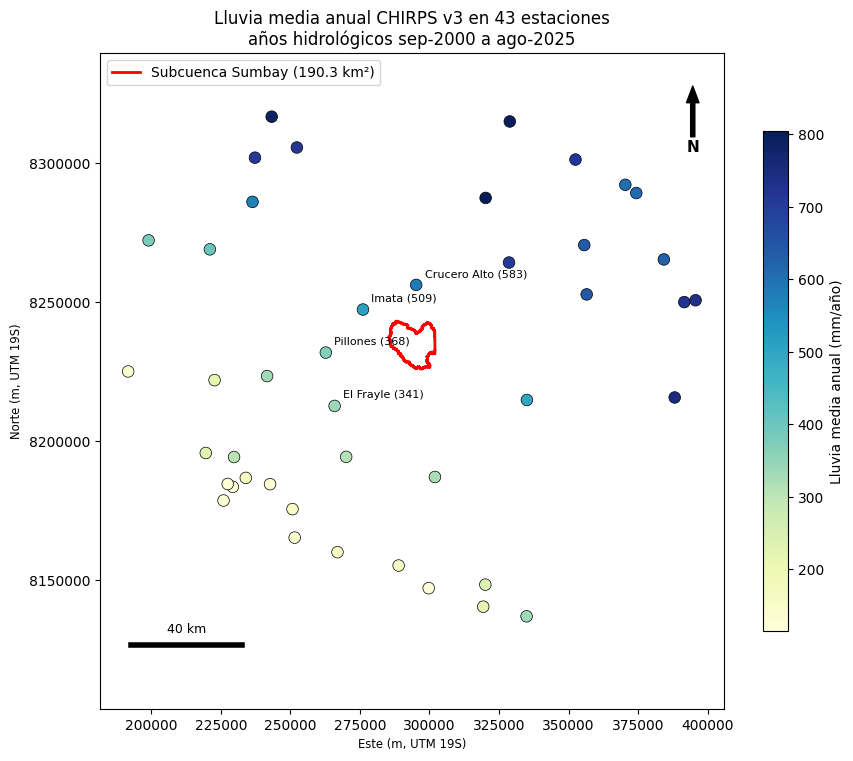

In [63]:
def barra_escala(ax, km):
    # dibuja una barra de escala en la esquina inferior izquierda (los ejes deben estar en metros)
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    x, y = x0 + 0.05 * (x1 - x0), y0 + 0.05 * (y1 - y0)
    ax.plot([x, x + km * 1000], [y, y], color="black", lw=4)
    ax.text(x + km * 500, y + 0.02 * (y1 - y0), f"{km} km", ha="center", fontsize=9)

def flecha_norte(ax):
    # flecha del norte en la esquina superior derecha
    ax.annotate("N", xy=(0.95, 0.95), xytext=(0.95, 0.85), xycoords="axes fraction",
                ha="center", fontsize=11, fontweight="bold", arrowprops=dict(facecolor="black", width=3, headwidth=9))

mapa_est = estaciones_utm.join(resumen["P_2000_2025"], on="codigo")   # pegar la lluvia media a cada punto

fig, ax = plt.subplots(figsize=(9, 8))
mapa_est.plot(ax=ax, column="P_2000_2025", cmap="YlGnBu", markersize=70, edgecolor="black", linewidth=0.5,
              legend=True, legend_kwds={"label": "Lluvia media anual (mm/año)", "shrink": 0.7})
cuenca_utm.plot(ax=ax, facecolor="none", edgecolor="red", linewidth=2)
for _, r in mapa_est[mapa_est.dist_km < 30].iterrows():              # nombres de las estaciones más cercanas
    ax.annotate(f"{r.nombre} ({r.P_2000_2025:.0f})", (r.geometry.x, r.geometry.y),
                xytext=(6, 6), textcoords="offset points", fontsize=8)
ax.plot([], [], color="red", lw=2, label=f"Subcuenca Sumbay ({AREA_KM2:.1f} km²)")   # entrada de leyenda
ax.margins(y=0.12)                               # margen arriba y abajo para la leyenda y la escala
ax.legend(loc="upper left")
ax.ticklabel_format(style="plain")                # coordenadas completas, sin "1e6"
ax.set_xlabel("Este (m, UTM 19S)"); ax.set_ylabel("Norte (m, UTM 19S)")
ax.set_title("Lluvia media anual CHIRPS v3 en 43 estaciones\naños hidrológicos sep-2000 a ago-2025")
barra_escala(ax, 40); flecha_norte(ax)
plt.tight_layout()
plt.savefig(PREFIJO + "fig1_lluvia_estaciones.png", dpi=150)
plt.show()

### 4.2 Régimen mensual de la lluvia en Imata

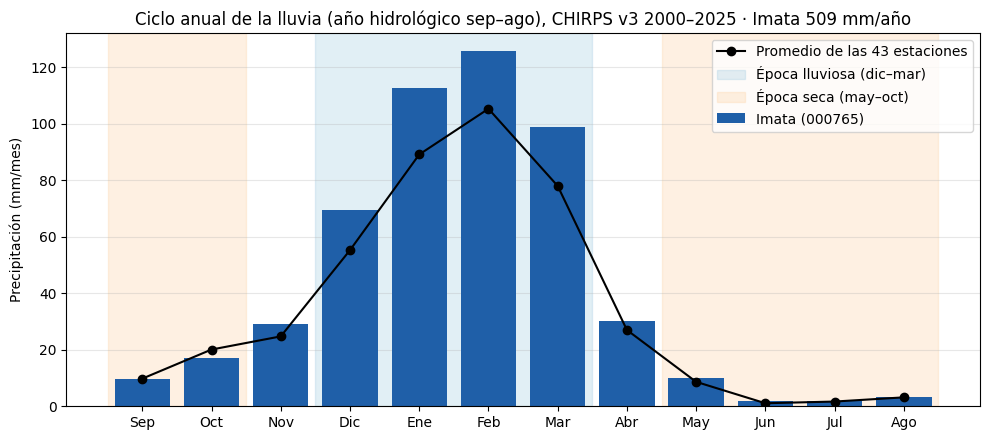

In [64]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(12)
ax.bar(x, clim[COD_IMATA], color="#1f5fa8", label="Imata (000765)", zorder=2)
ax.plot(x, clim.mean(axis=1), "o-", color="black", label="Promedio de las 43 estaciones", zorder=3)
ax.axvspan(2.5, 6.5, color="#9ecae1", alpha=0.3, label="Época lluviosa (dic–mar)", zorder=0)
ax.axvspan(7.5, 11.5, color="#fdd0a2", alpha=0.3, label="Época seca (may–oct)", zorder=0)
ax.axvspan(-0.5, 1.5, color="#fdd0a2", alpha=0.3, zorder=0)                  # sep–oct también son época seca
ax.set_xticks(x); ax.set_xticklabels(clim.index)
ax.set_ylabel("Precipitación (mm/mes)")
ax.set_title(f"Ciclo anual de la lluvia (año hidrológico sep–ago), CHIRPS v3 2000–2025 · "
             f"Imata {clim[COD_IMATA].sum():.0f} mm/año")
ax.legend(); ax.grid(axis="y", alpha=0.3, zorder=1)
plt.tight_layout()
plt.savefig(PREFIJO + "fig2_regimen_imata.png", dpi=150)
plt.show()

### 4.3 Lluvia media anual sobre la cuenca, malla de 1 km: p = 2 frente a p = 5

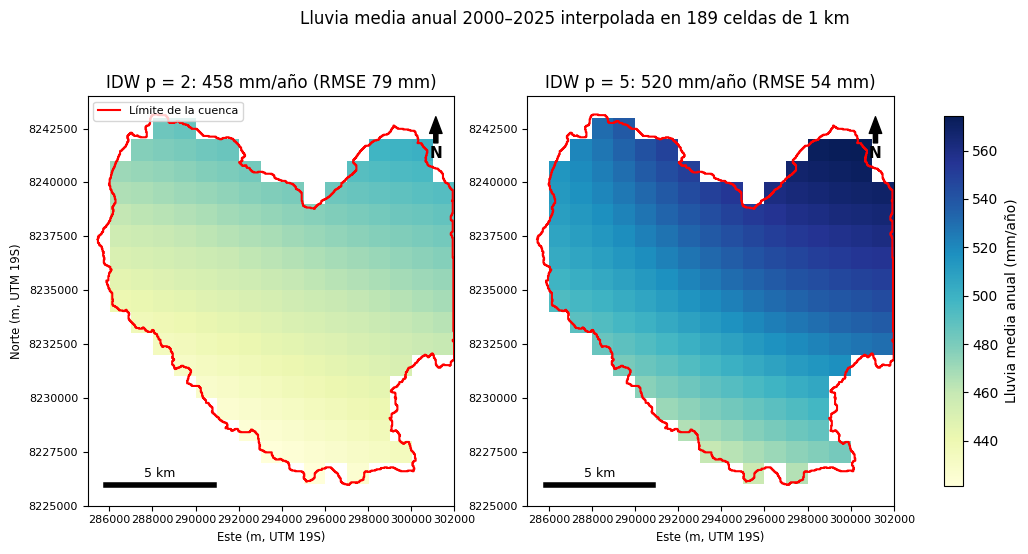

In [65]:
extent = (xmin, xmax, ymin, ymax)                         # borde del recuadro, en metros
vmin = min(np.nanmin(np.where(en_cuenca, mapa_anual[p], np.nan)) for p in POTENCIAS_COMPARAR)
vmax = max(np.nanmax(np.where(en_cuenca, mapa_anual[p], np.nan)) for p in POTENCIAS_COMPARAR)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, p in zip(axes, POTENCIAS_COMPARAR):
    img = ax.imshow(np.where(en_cuenca, mapa_anual[p], np.nan), extent=extent,
                    cmap="YlGnBu", vmin=vmin, vmax=vmax)              # solo las celdas de la cuenca
    cuenca_utm.boundary.plot(ax=ax, color="red", linewidth=1.5)
    ax.set_title(f"IDW p = {p}: {P_MEDIA[f'P_p{p}']:.0f} mm/año (RMSE {RMSE[p]:.0f} mm)")
    ax.set_xlabel("Este (m, UTM 19S)"); ax.set_ylabel("")         # se borra la etiqueta automática en inglés
    ax.ticklabel_format(style="plain"); ax.tick_params(labelsize=8)
    barra_escala(ax, 5); flecha_norte(ax)
axes[0].set_ylabel("Norte (m, UTM 19S)")
axes[0].plot([], [], color="red", lw=1.5, label="Límite de la cuenca"); axes[0].legend(loc="upper left", fontsize=8)
fig.colorbar(img, ax=axes, label="Lluvia media anual (mm/año)", shrink=0.8)
fig.suptitle(f"Lluvia media anual 2000–2025 interpolada en {N_CELDAS} celdas de 1 km")
plt.savefig(PREFIJO + "fig3_mapa_p2_p5.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.4 Validación cruzada y variabilidad entre años

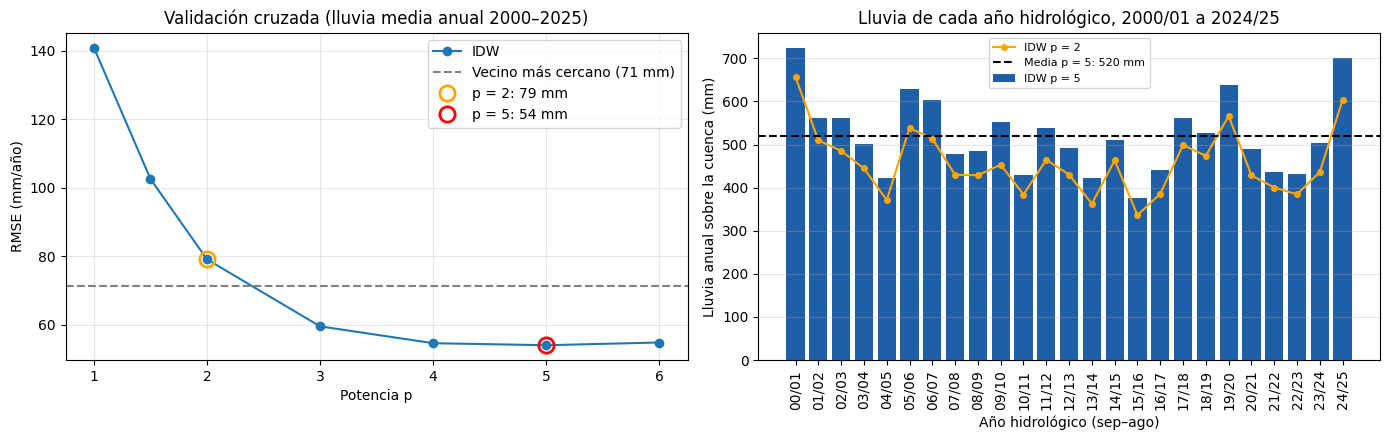

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ax = axes[0]                                              # curva de error según la potencia
ax.plot(cv["potencia"], cv["rmse_mm"], "o-", color="#1f78b4", label="IDW")
ax.axhline(ERROR_VECINO_MM, color="gray", ls="--", label=f"Vecino más cercano ({ERROR_VECINO_MM:.0f} mm)")
for p, c in zip(POTENCIAS_COMPARAR, ["orange", "red"]):
    ax.plot(p, RMSE[p], "o", ms=11, mfc="none", mew=2, color=c, label=f"p = {p}: {RMSE[p]:.0f} mm")
ax.set_xlabel("Potencia p"); ax.set_ylabel("RMSE (mm/año)")
ax.set_title("Validación cruzada (lluvia media anual 2000–2025)")
ax.grid(alpha=0.3); ax.legend()

ax = axes[1]                                              # lluvia de cada año hidrológico sobre la cuenca
etiquetas = [f"{a % 100:02d}/{(a + 1) % 100:02d}" for a in P_cuenca_anual.index]
ax.bar(etiquetas, P_cuenca_anual["P_p5"], color="#1f5fa8", label="IDW p = 5")
ax.plot(etiquetas, P_cuenca_anual["P_p2"], "o-", color="orange", ms=4, label="IDW p = 2")
ax.axhline(P_MEDIA["P_p5"], color="black", ls="--", label=f"Media p = 5: {P_MEDIA['P_p5']:.0f} mm")
ax.set_ylabel("Lluvia anual sobre la cuenca (mm)"); ax.set_xlabel("Año hidrológico (sep–ago)")
ax.set_title("Lluvia de cada año hidrológico, 2000/01 a 2024/25")
ax.tick_params(axis="x", rotation=90); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(PREFIJO + "fig4_validacion_y_anios.png", dpi=150)
plt.show()

### 4.5 Balance mensual P − ET de la cuenca (figura principal)

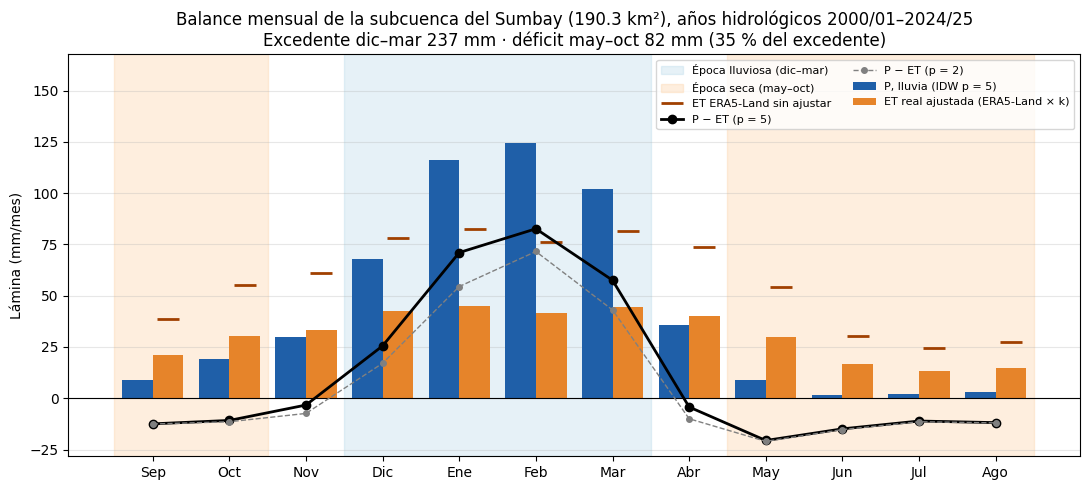

In [67]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(12)
ax.axvspan(2.5, 6.5, color="#9ecae1", alpha=0.25, zorder=0, label="Época lluviosa (dic–mar)")
ax.axvspan(7.5, 11.5, color="#fdd0a2", alpha=0.35, zorder=0, label="Época seca (may–oct)")
ax.axvspan(-0.5, 1.5, color="#fdd0a2", alpha=0.35, zorder=0)
ax.bar(x - 0.2, clim_bal["P_p5"], width=0.4, color="#1f5fa8", zorder=2, label="P, lluvia (IDW p = 5)")
ax.bar(x + 0.2, clim_bal["ET"], width=0.4, color="#e6842a", zorder=2, label="ET real ajustada (ERA5-Land × k)")
ax.plot(x + 0.2, clim_bal["ET_ERA5"], "_", color="#a04000", ms=16, mew=2, zorder=3, label="ET ERA5-Land sin ajustar")
ax.plot(x, clim_bal["B_p5"], "o-", color="black", lw=2, zorder=3, label="P − ET (p = 5)")
ax.plot(x, clim_bal["B_p2"], "o--", color="gray", lw=1, ms=4, zorder=3, label="P − ET (p = 2)")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(clim_bal.index)
ax.set_ylabel("Lámina (mm/mes)"); ax.set_ylim(top=clim_bal[["P_p5", "ET_ERA5"]].max().max() * 1.35)
ax.set_title(f"Balance mensual de la subcuenca del Sumbay ({AREA_KM2:.1f} km²), años hidrológicos 2000/01–2024/25\n"
             f"Excedente dic–mar {EXCEDENTE_MM:.0f} mm · déficit may–oct {DEFICIT_MM:.0f} mm "
             f"({DEPENDENCIA:.0f} % del excedente)")
ax.legend(fontsize=8, ncol=2, loc="upper right"); ax.grid(axis="y", alpha=0.3, zorder=1)
plt.tight_layout()
plt.savefig(PREFIJO + "fig5_balance_mensual.png", dpi=150)
plt.show()

### 4.6 Balance de cada año hidrológico y volumen disponible

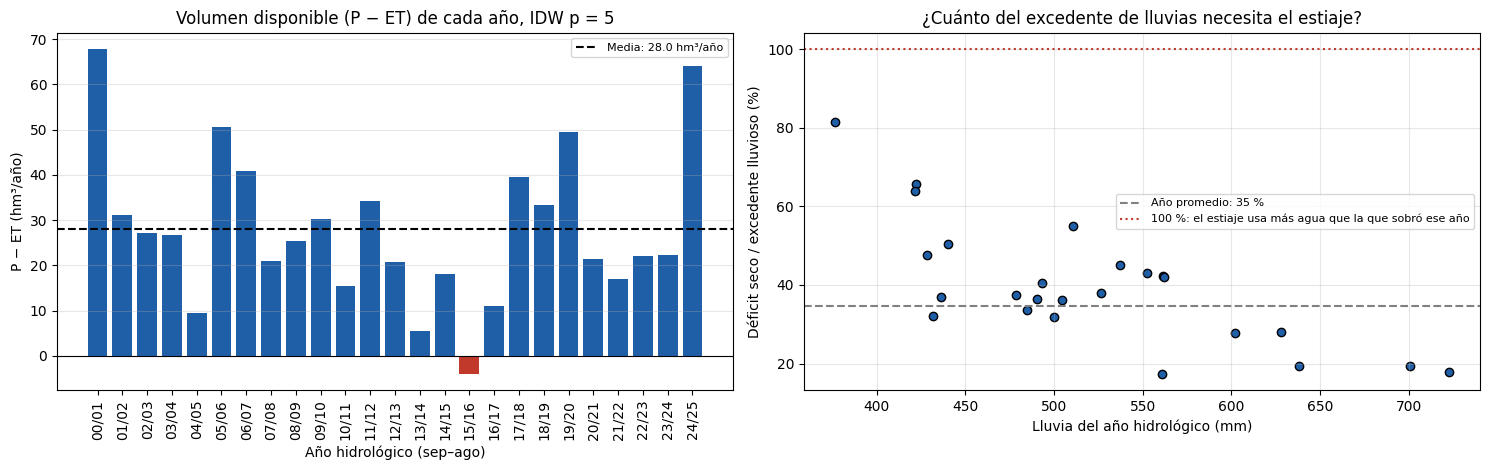

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
etiq = [f"{a % 100:02d}/{(a + 1) % 100:02d}" for a in por_año.index]

ax = axes[0]                                               # volumen disponible de cada año
colores = np.where(por_año["vol_disponible_hm3"] >= 0, "#1f5fa8", "#c0392b")
ax.bar(etiq, por_año["vol_disponible_hm3"], color=colores)
ax.axhline(por_año["vol_disponible_hm3"].mean(), color="black", ls="--",
           label=f"Media: {por_año['vol_disponible_hm3'].mean():.1f} hm³/año")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("P − ET (hm³/año)"); ax.set_xlabel("Año hidrológico (sep–ago)")
ax.set_title("Volumen disponible (P − ET) de cada año, IDW p = 5")
ax.tick_params(axis="x", rotation=90); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)

ax = axes[1]                                               # dependencia del estiaje frente a la lluvia del año
ax.scatter(por_año["P_mm"], por_año["dependencia_%"], color="#1f5fa8", edgecolor="black")
for a, r in por_año[por_año["dependencia_%"] > 100].iterrows():      # etiquetas solo de los años críticos
    ax.annotate(f"{a % 100:02d}/{(a + 1) % 100:02d}", (r.P_mm, r["dependencia_%"]), fontsize=7,
                xytext=(3, 3), textcoords="offset points")
ax.axhline(DEPENDENCIA, color="gray", ls="--", label=f"Año promedio: {DEPENDENCIA:.0f} %")
ax.axhline(100, color="#c0392b", ls=":", label="100 %: el estiaje usa más agua que la que sobró ese año")
ax.set_xlabel("Lluvia del año hidrológico (mm)"); ax.set_ylabel("Déficit seco / excedente lluvioso (%)")
ax.set_title("¿Cuánto del excedente de lluvias necesita el estiaje?")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PREFIJO + "fig6_balance_anual.png", dpi=150)
plt.show()

### 4.7 Contraste de fuentes: ET y lluvia

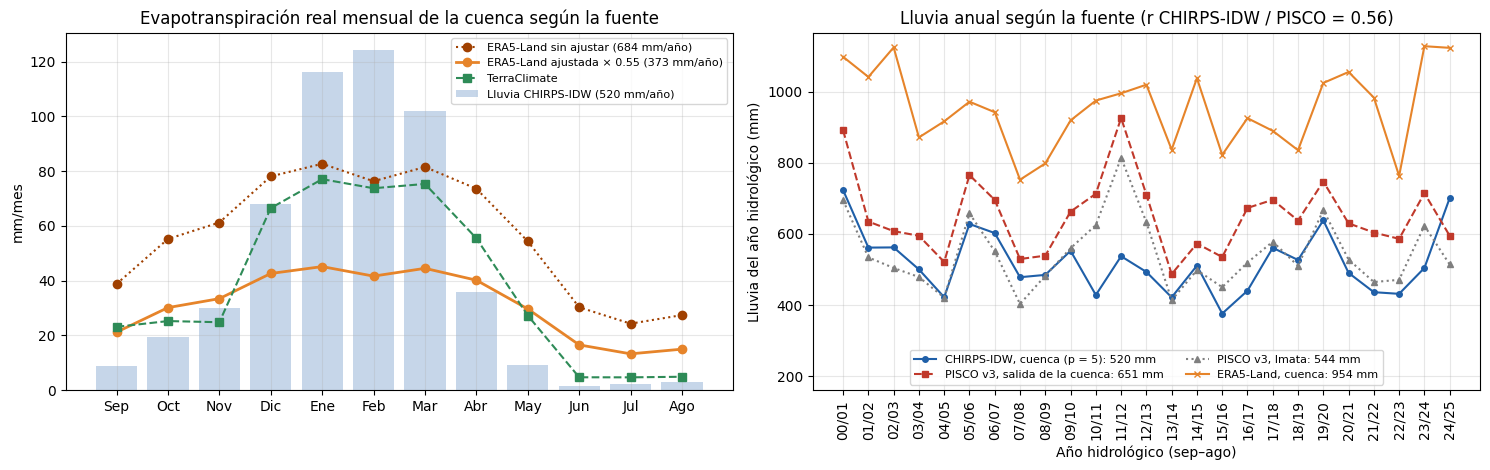

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

ax = axes[0]                                              # ciclo anual de la ET según cada fuente
x = np.arange(12)
ax.plot(x, clim_bal["ET_ERA5"], "o:", color="#a04000", label=f"ERA5-Land sin ajustar ({ET_era5_anual:.0f} mm/año)")
ax.plot(x, clim_bal["ET"], "o-", color="#e6842a", lw=2, label=f"ERA5-Land ajustada × {K_AJUSTE:.2f} ({ET_aj_anual:.0f} mm/año)")
if clim_bal["ET_TC"].notna().any():
    ax.plot(x, clim_bal["ET_TC"], "s--", color="#2e8b57", label="TerraClimate")
ax.bar(x, clim_bal["P_p5"], color="#1f5fa8", alpha=0.25, label=f"Lluvia CHIRPS-IDW ({P_MEDIA['P_p5']:.0f} mm/año)")
ax.set_xticks(x); ax.set_xticklabels(clim_bal.index)
ax.set_ylabel("mm/mes"); ax.set_title("Evapotranspiración real mensual de la cuenca según la fuente")
ax.legend(fontsize=8); ax.grid(alpha=0.3)

ax = axes[1]                                              # lluvia de cada año según cada fuente
etiq = [f"{a % 100:02d}/{(a + 1) % 100:02d}" for a in comp_anual.index]
estilos = {"CHIRPS_IDW_cuenca": ("o-", "#1f5fa8", "CHIRPS-IDW, cuenca (p = 5)"),
           "PISCO_salida": ("s--", "#c0392b", "PISCO v3, salida de la cuenca"),
           "PISCO_Imata": ("^:", "#7f7f7f", "PISCO v3, Imata"),
           "ERA5_cuenca": ("x-", "#e6842a", "ERA5-Land, cuenca")}
for col, (est_l, color, etiqueta) in estilos.items():
    ax.plot(etiq, comp_anual[col], est_l, color=color, ms=4, label=f"{etiqueta}: {comp_anual[col].mean():.0f} mm")
ax.set_ylabel("Lluvia del año hidrológico (mm)"); ax.set_xlabel("Año hidrológico (sep–ago)")
ax.set_title(f"Lluvia anual según la fuente (r CHIRPS-IDW / PISCO = {r_cuenca:.2f})")
ax.set_ylim(bottom=comp_anual.min().min() * 0.45)        # espacio abajo para la leyenda
ax.tick_params(axis="x", rotation=90); ax.legend(fontsize=8, ncol=2, loc="lower center"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PREFIJO + "fig7_contraste_fuentes.png", dpi=150)
plt.show()

## 5. Interpretación
1: La subcuenca del rio Sumbay recibe 520 mm/año equivalentes aun volumen de agua de 99 hm3, con una p=5 y unos 54 mm/ año (RMSE de la validacion cruzada).
2. Ya teniendo conocimeinto de nuesta Precipitacion anual, y con una ET_mm de 373 mm/año, a realizar la sustraccion de P_mm-ET_mm = 1147 mm/año equivalentes a 28 hm3/año con un rango de 11 a 53 hm3, por los datos usados de distintas fuentes uno de PISCOv3, que considera mas estaciones que CHIRPS, y terra climate que da un valor alto en ET_mm de 462.4.
3.  El estiaje de la subcuenca del rio sumbay depende del agua almacenada en las lluvias, un 35%, en un año promedio, y hasta un 81%  en un año seco, para el caudal de mayo a octubre, significa para mantener un caudal constante en años de poca lluvia y para los meses secos de mayo a octubre, se puede depender hasta de 81% del excedente.
4. Debemos considerar que los resultados obtenidos son estimaciones, ya que sin caudales observados en el punto de salida de la subcuenca, no se pued validar los resultados, sin embargo para SEDAPR y la ANA estas estimaciones, permiten tener una tener antecedentes de como se comporta el estiaje a lo largo del año, y como esto  afecta al nivel de agua del rio chili, y su caudal a la represa aguada blanca.

### Productos guardados

In [70]:
productos = [PREFIJO + "P_mensual_estaciones_2000_2025.csv", PREFIJO + "P_anual_media_estaciones.csv",
             PREFIJO + "P_climatologia_mensual_estaciones.csv",
             PREFIJO + "fig1_lluvia_estaciones.png", PREFIJO + "fig2_regimen_imata.png",
             PREFIJO + "validacion_cruzada.csv", PREFIJO + "P_cuenca_mensual_2000_2025.csv",
             PREFIJO + "sensibilidad_potencia.csv", PREFIJO + "P_cuenca_climatologia.csv",
             PREFIJO + "P_anual_idw_p2_1km.tif", PREFIJO + "P_anual_idw_p5_1km.tif",
             PREFIJO + "fig3_mapa_p2_p5.png", PREFIJO + "fig4_validacion_y_anios.png",
             PREFIJO + "balance_mensual_2000_2025.csv", PREFIJO + "balance_climatologia_mensual.csv",
             PREFIJO + "balance_por_epoca.csv", PREFIJO + "balance_por_año.csv",
             PREFIJO + "fig5_balance_mensual.png", PREFIJO + "fig6_balance_anual.png",
             PREFIJO + "contraste_lluvia_anual.csv", PREFIJO + "sensibilidad_balance.csv",
             PREFIJO + "fig7_contraste_fuentes.png"]
try:
    from google.colab import files                 # solo existe dentro de Colab
    for f in productos:
        files.download(f)                          # descarga cada archivo a la computadora
except ImportError:
    print("Fuera de Colab: los archivos quedaron en la carpeta de trabajo:", productos)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (34 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>